
<a href="https://colab.research.google.com/github/CienciaDatosUdea/005_CCA_Estudiantes/blob/main/Laboratorios/10_Lab_langevineP.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Movimiento browniano

Una partícula inmersa en un líquido experimenta fricción y
fluctuaciones producidas por las colisiones moleculares.
Para una partícula libre, la ecuación de Langevin es

$$
m\frac{d^2x}{dt^2}
=
-\gamma\frac{dx}{dt}+\xi(t),
$$

donde $m$ es la masa, $\gamma$ es el coeficiente de fricción
y $\xi(t)$ es la fuerza fluctuante.

## Propiedades del ruido térmico

La fuerza fluctuante tiene media cero:

$$
\langle\xi(t)\rangle=0.
$$

Esto significa que las fluctuaciones no tienen una dirección
preferida en promedio.

Para un líquido en equilibrio térmico, la correlación es

$$
\langle\xi(t)\xi(t')\rangle
=
2\gamma k_BT\,\delta(t-t').
$$

La delta de Dirac es una distribución matemática, definida
por su acción dentro de una integral:

$$
\int_{-\infty}^{\infty}
\delta(t-t')f(t')\,dt'=f(t).
$$

La correlación del ruido blanco se concentra en tiempos
coincidentes y se anula para tiempos distintos. El ruido
blanco se interpreta mediante sus integrales temporales.

## Formulación mediante un proceso de Wiener

Definimos la velocidad:

$$
v=\frac{dx}{dt}.
$$

El sistema se escribe formalmente como

$$
\begin{aligned}
\frac{dx}{dt}&=v,\\
m\frac{dv}{dt}&=-\gamma v+\xi(t).
\end{aligned}
$$

Mediante un proceso de Wiener, su formulación precisa es

$$
\begin{aligned}
dx_t&=v_t\,dt,\\
m\,dv_t&=-\gamma v_t\,dt
+\sqrt{2\gamma k_BT}\,dW_t.
\end{aligned}
$$

Los incrementos de Wiener en intervalos disjuntos son
independientes y satisfacen

$$
\Delta W_n
=
W_{t_{n+1}}-W_{t_n}
\sim\mathcal{N}(0,\Delta t).
$$

Para generarlos numéricamente usamos

$$
\Delta W_n=\sqrt{\Delta t}\,Z_n,
\qquad
Z_n\sim\mathcal{N}(0,1),
$$

con un nuevo $Z_n$ independiente en cada paso.

## Régimen sobreamortiguado

En escalas temporales grandes frente a $m/\gamma$, podemos
despreciar la inercia:

$$
\gamma\frac{dx}{dt}=\xi(t).
$$

La ecuación estocástica se reduce a

$$
dx_t=\sqrt{2D}\,dW_t,
\qquad
D=\frac{k_BT}{\gamma}.
$$

Para una posición inicial fija $x_0$, la solución es

$$
x_t=x_0+\sqrt{2D}\,W_t,
\qquad W_0=0.
$$

La media permanece en la posición inicial y la varianza
aumenta linealmente:

$$
\mathbb{E}[x_t]=x_0,
\qquad
\operatorname{Var}(x_t)=2Dt.
$$

Entre dos tiempos, la actualización exacta de este modelo es

$$
x_{n+1}
=
x_n+\sqrt{2D\,\Delta t}\,Z_n,
\qquad
Z_n\sim\mathcal{N}(0,1).
$$

Esta expresión describe una partícula libre en el régimen
sobreamortiguado.

Al incorporar un resorte, añadimos una deriva restauradora:

$$
dx_t
=
-\frac{k}{\gamma}x_t\,dt
+
\sqrt{2D}\,dW_t.
$$

Su aproximación de Euler–Maruyama es

$$
x_{n+1}
=
x_n-\frac{k}{\gamma}x_n\Delta t
+\sqrt{2D\,\Delta t}\,Z_n.
$$

El resorte confina las posiciones y el ruido mantiene las
fluctuaciones. A tiempos largos, la distribución se aproxima
a una gaussiana con media cero y varianza $k_BT/k$.

# Movimiento Browniano

\begin{equation}
\frac{d^2x}{dt^2}=-\gamma \frac{dx}{dt} + \xi(t)
\end{equation}

$\eta(t)$ Fuerza aleatoria producida por las colisiones colisiones moleculares $\langle \eta(t)\rangle=0.$, en promedio las colisiones que se presentan dan cero.
Para un liquido en equilibrio térmico, la intensidad viene dada por:

$\langle\xi(t)\xi(t') \rangle = 2\gamma k_B T  \delta(t-t') $

Para $\delta(\Delta t) = 0$, si $t!=t'$,

Para $\delta(\Delta t) = \infty$, si $t = t'$,



\begin{equation}
\frac{dx}{dt}=v
\end{equation}


\begin{equation}
\frac{dv}{dt}=-\gamma  \frac{dx}{dt} + \xi(t)
\end{equation}

El sistema de ecuaciones, se transforma, en, empleando un proceo de Wigner:


\begin{equation}
\begin{aligned}
dx(t)&=v(t)\,dt,\\
m\,dv(t)&=-\gamma v(t)\,dt
+\sqrt{2\gamma k_BT}\,dW(t).
\end{aligned}
\end{equation}



Cuya solución es

\begin{equation}
x(t+\Delta t)
=
x(t)+\sqrt{2D\,\Delta t}\,Z,
\qquad Z\sim\mathcal N(0,1).
\end{equation}



In [1]:
import numpy as np
import matplotlib.pyplot as plt

# Parámetros físicos (unidades arbitrarias)
kB_T = 1.0      # k_B T
gamma = 1.0     # coeficiente de fricción
D = kB_T / gamma
k = 2.0         # constante del resorte (para el caso con fuerza externa)

dt = 0.01
n_pasos = 2000
n_part = 2000   # número de partículas (trayectorias independientes)
t = np.arange(n_pasos + 1) * dt
rng = np.random.default_rng(0)


 # Simulacion del movimiento browniano

 Realizar un codigo para simular el movimiento browniano sin fuerza externa y con fuerza externa de la forma f=-kx

In [2]:
# --- Movimiento browniano libre (sobreamortiguado): x_{n+1} = x_n + sqrt(2 D dt) Z_n ---
def browniano_libre(x0, D, dt, n_pasos, n_part, rng):
    Z = rng.standard_normal((n_part, n_pasos))
    incrementos = np.sqrt(2 * D * dt) * Z
    x = np.empty((n_part, n_pasos + 1))
    x[:, 0] = x0
    x[:, 1:] = x0 + np.cumsum(incrementos, axis=1)   # actualización exacta, vectorizada
    return x

# --- Con resorte f = -k x (Euler–Maruyama): x_{n+1} = x_n - (k/gamma) x_n dt + sqrt(2 D dt) Z_n ---
def browniano_resorte(x0, k, gamma, D, dt, n_pasos, n_part, rng):
    x = np.empty((n_part, n_pasos + 1))
    x[:, 0] = x0
    for n in range(n_pasos):
        Z = rng.standard_normal(n_part)
        x[:, n + 1] = x[:, n] - (k / gamma) * x[:, n] * dt + np.sqrt(2 * D * dt) * Z
    return x

x_libre = browniano_libre(0.0, D, dt, n_pasos, n_part, rng)
x_resorte = browniano_resorte(0.0, k, gamma, D, dt, n_pasos, n_part, rng)


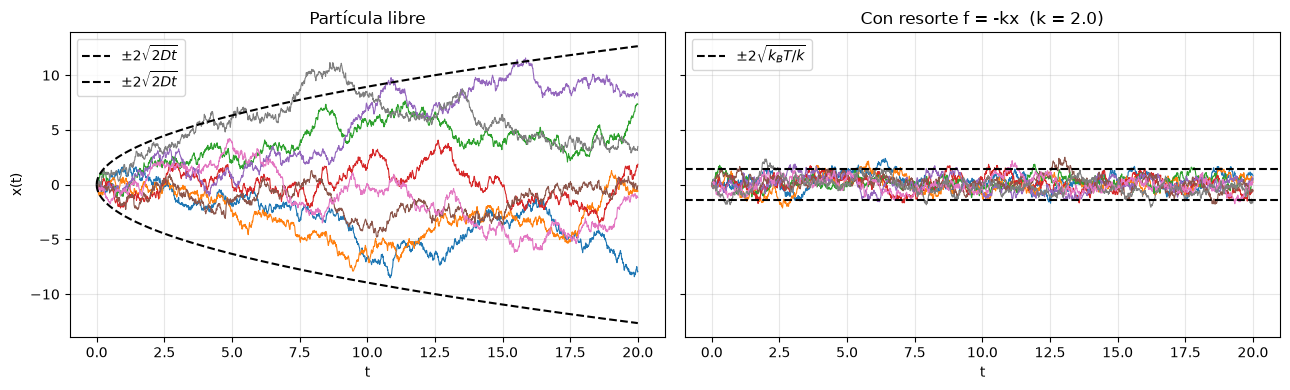

In [3]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4), sharey=True)
for i in range(8):
    ax[0].plot(t, x_libre[i], lw=0.8)
    ax[1].plot(t, x_resorte[i], lw=0.8)
s = np.sqrt(2 * D * t)
ax[0].plot(t, 2 * s, "k--", t, -2 * s, "k--", label=r"$\pm 2\sqrt{2Dt}$")
ax[1].axhline(2 * np.sqrt(kB_T / k), color="k", ls="--", label=r"$\pm 2\sqrt{k_BT/k}$")
ax[1].axhline(-2 * np.sqrt(kB_T / k), color="k", ls="--")
ax[0].set_title("Partícula libre"); ax[1].set_title(f"Con resorte f = -kx  (k = {k})")
for a in ax: a.set_xlabel("t"); a.legend(loc="upper left"); a.grid(alpha=.3)
ax[0].set_ylabel("x(t)")
plt.tight_layout(); plt.show()


## Verificación de la teoría

- **Partícula libre:** $\mathbb{E}[x_t] = x_0$ y $\operatorname{Var}(x_t) = 2Dt$ (difusión).
- **Con resorte (proceso de Ornstein–Uhlenbeck):** $\operatorname{Var}(x_t) = \frac{k_BT}{k}\left(1 - e^{-2kt/\gamma}\right) \to \frac{k_BT}{k}$, y la distribución estacionaria es una gaussiana $\mathcal{N}(0, k_BT/k)$.

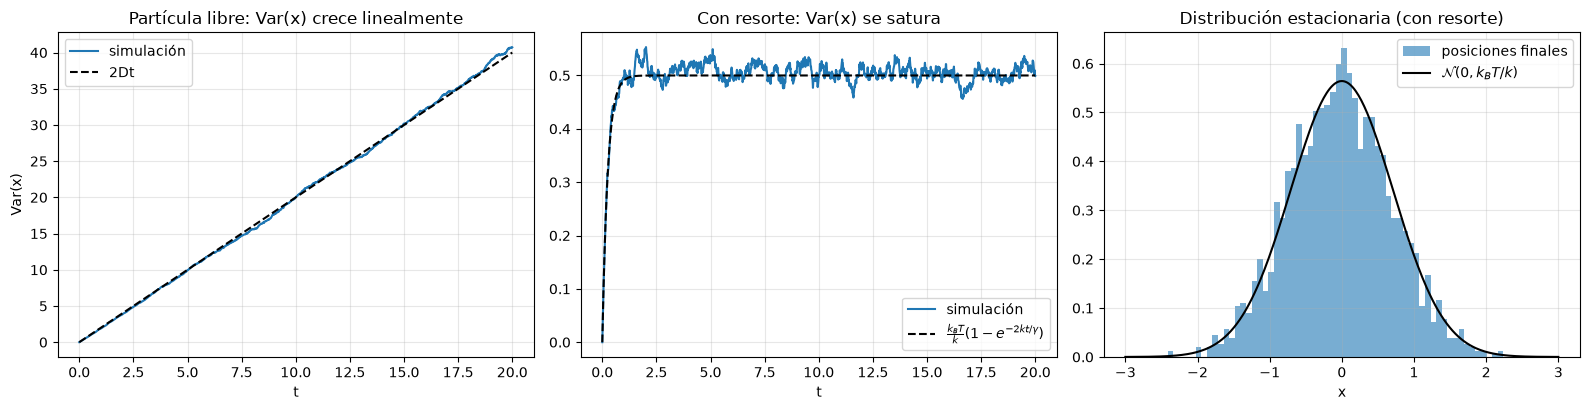

Libre:   media final = -0.0434 (teoría 0)   pendiente de Var(t) = 2.0294 (teoría 2D = 2.0)
Resorte: media = -0.0061 (teoría 0)   varianza estacionaria = 0.5029   teoría k_BT/k = 0.5000   (con corrección de dt: 0.5051)


In [4]:
var_libre = x_libre.var(axis=0)
var_resorte = x_resorte.var(axis=0)
var_ou = kB_T / k * (1 - np.exp(-2 * k * t / gamma))

fig, ax = plt.subplots(1, 3, figsize=(16, 4.2))
ax[0].plot(t, var_libre, label="simulación"); ax[0].plot(t, 2 * D * t, "k--", label="2Dt")
ax[0].set_title("Partícula libre: Var(x) crece linealmente"); ax[0].set_xlabel("t"); ax[0].set_ylabel("Var(x)")
ax[1].plot(t, var_resorte, label="simulación"); ax[1].plot(t, var_ou, "k--", label=r"$\frac{k_BT}{k}(1-e^{-2kt/\gamma})$")
ax[1].set_title("Con resorte: Var(x) se satura"); ax[1].set_xlabel("t")
xs = np.linspace(-3, 3, 300)
ax[2].hist(x_resorte[:, -1], bins=60, density=True, alpha=0.6, label="posiciones finales")
ax[2].plot(xs, np.exp(-xs**2 * k / (2 * kB_T)) / np.sqrt(2 * np.pi * kB_T / k), "k", label=r"$\mathcal{N}(0, k_BT/k)$")
ax[2].set_title("Distribución estacionaria (con resorte)"); ax[2].set_xlabel("x")
for a in ax: a.legend(); a.grid(alpha=.3)
plt.tight_layout(); plt.show()

# Pendiente de Var(x) vs t para la partícula libre -> 2D
pend = np.polyfit(t, var_libre, 1)[0]
print(f"Libre:   media final = {x_libre[:, -1].mean():+.4f} (teoría 0)   pendiente de Var(t) = {pend:.4f} (teoría 2D = {2*D})")
# Varianza estacionaria: promedio en la segunda mitad (ya en equilibrio, ya que 2k/gamma * t >> 1)
v_est = x_resorte[:, n_pasos // 2:].var()
v_disc = (kB_T / k) / (1 - k * dt / (2 * gamma))   # corrección por discretización de Euler–Maruyama
print(f"Resorte: media = {x_resorte[:, n_pasos//2:].mean():+.4f} (teoría 0)   varianza estacionaria = {v_est:.4f}"
      f"   teoría k_BT/k = {kB_T/k:.4f}   (con corrección de dt: {v_disc:.4f})")


# Con modelos tipo Score

# Dinámica de Langevin con un campo score

Para una densidad de probabilidad $p_\theta(\mathbf{x})$,
definimos el campo score como

$$
\mathbf{s}_\theta(\mathbf{x})
=
\nabla_{\mathbf{x}}\log p_\theta(\mathbf{x}).
$$

Este campo apunta hacia la dirección de máximo crecimiento
local del logaritmo de la densidad.

## Relación entre el score y la fuerza

Para una distribución de Boltzmann,

$$
p_\theta(\mathbf{x})
=
\frac{1}{Z_\theta}
\exp\left[-\frac{U_\theta(\mathbf{x})}{k_BT}\right],
$$

el score es

$$
\mathbf{s}_\theta(\mathbf{x})
=
-\frac{1}{k_BT}\nabla_{\mathbf{x}}U_\theta(\mathbf{x}).
$$

Como la fuerza es $\mathbf{F}_\theta=-\nabla U_\theta$,

$$
\mathbf{F}_\theta(\mathbf{x})
=
k_BT\,\mathbf{s}_\theta(\mathbf{x}).
$$

## Ecuación estocástica

La dinámica sobreamortiguada es

$$
d\mathbf{X}_t
=
\frac{\mathbf{F}_\theta(\mathbf{X}_t)}{\gamma}\,dt
+
\sqrt{2D}\,d\mathbf{W}_t,
\qquad
D=\frac{k_BT}{\gamma}.
$$

Sustituyendo la fuerza por su expresión en términos del score:

$$
d\mathbf{X}_t
=
D\,\mathbf{s}_\theta(\mathbf{X}_t)\,dt
+
\sqrt{2D}\,d\mathbf{W}_t.
$$

El campo produce un desplazamiento dirigido y el ruido
mantiene las fluctuaciones. Durante esta evolución,
$\theta$ permanece fijo.

## Incrementos de Wiener

En $d$ dimensiones,

$$
\Delta\mathbf{W}_n
=
\sqrt{\Delta t}\,\boldsymbol{\epsilon}_n,
\qquad
\boldsymbol{\epsilon}_n\sim\mathcal{N}(\mathbf{0},I_d),
$$

con nuevos vectores independientes en cada paso.

## Actualización numérica

La aproximación de Euler–Maruyama es

$$
\mathbf{X}_{n+1}
=
\mathbf{X}_n
+
D\,\mathbf{s}_\theta(\mathbf{X}_n)\Delta t
+
\sqrt{2D\Delta t}\,\boldsymbol{\epsilon}_n.
$$

En unidades donde $D=1$:

$$
\mathbf{X}_{n+1}
=
\mathbf{X}_n
+
\mathbf{s}_\theta(\mathbf{X}_n)\Delta t
+
\sqrt{2\Delta t}\,\boldsymbol{\epsilon}_n.
$$

Con el score exacto y condiciones adecuadas de convergencia,
la dinámica continua reproduce $p_\theta$ a tiempos largos.
La actualización numérica introduce un error de discretización.

## Ejemplo: distribución gaussiana

Para una gaussiana con media $\boldsymbol{\mu}$ y
covarianza $vI_d$,

$$
\mathbf{s}(\mathbf{x})
=
-\frac{\mathbf{x}-\boldsymbol{\mu}}{v}.
$$



In [5]:
import numpy as np
import matplotlib.pyplot as plt

# Gaussiana objetivo
mu = 0.0
varianza = 1.0

def densidad(x):
    return np.exp(-(x - mu)**2 / (2 * varianza)) / np.sqrt(
        2 * np.pi * varianza
    )

def score(x):
    return -(x - mu) / varianza



In [6]:
rng = np.random.default_rng(42)

n_trayectorias = 200
n_pasos = 1_000
dt = 0.01

# Todas las trayectorias comienzan en la misma posición
x = np.zeros((n_trayectorias, n_pasos))
np.shape(x)
t = np.arange(n_pasos+1 ) * dt

In [7]:
x = np.zeros((n_trayectorias, n_pasos + 1))

# Todas las trayectorias comienzan en cero
x[:, 0] = 0.0

for k in range(n_trayectorias):
    for j in range(n_pasos):
        ruido = rng.normal()

        x[k, j + 1] = (
            x[k, j]
            + dt * score(x[k, j])
            + np.sqrt(2 * dt) * ruido
        )

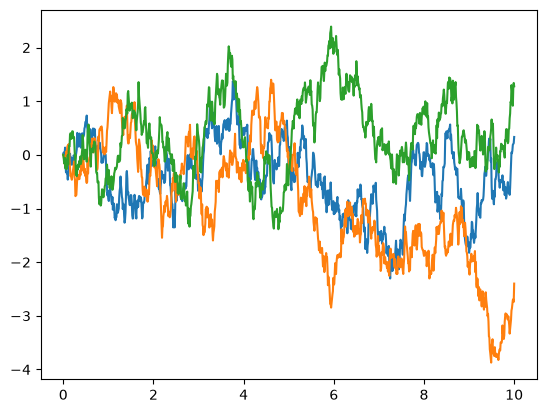

In [8]:
plt.plot(t, x[0])
plt.plot(t, x[1])
plt.plot(t, x[2])

In [9]:
x=np.concat(x)

Media de las muestras:    -0.0092
Varianza de las muestras: 0.9434
Varianza teórica discreta: 1.0050


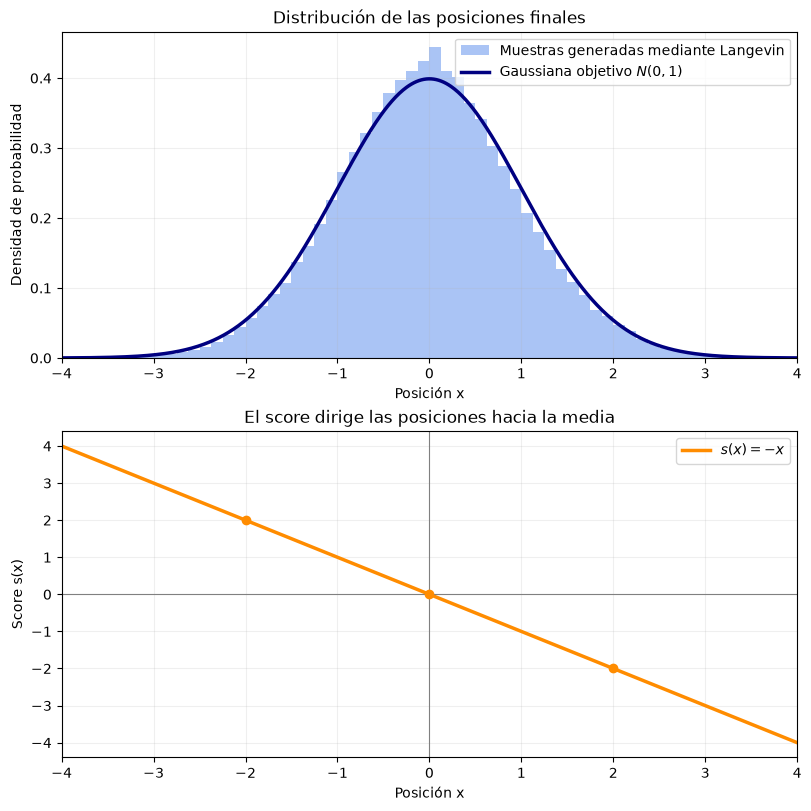

In [10]:
# Resultados
print(f"Media de las muestras:    {np.mean(x):.4f}")
print(f"Varianza de las muestras: {np.var(x):.4f}")

# Varianza estacionaria de la actualización discreta
varianza_discreta = varianza / (1 - dt / (2 * varianza))
print(f"Varianza teórica discreta: {varianza_discreta:.4f}")


# Gráficas
eje = np.linspace(-4, 4, 600)

fig, axes = plt.subplots(
    2, 1, figsize=(8, 8), constrained_layout=True
)

# Densidad objetivo e histograma de posiciones finales
axes[0].hist(
    x,
    bins=np.linspace(-4, 4, 65),
    density=True,
    color="cornflowerblue",
    alpha=0.55,
    label="Muestras generadas mediante Langevin"
)

axes[0].plot(
    eje,
    densidad(eje),
    color="navy",
    linewidth=2.5,
    label=r"Gaussiana objetivo ${N}(0,1)$"
)

axes[0].set(
    title="Distribución de las posiciones finales",
    xlabel="Posición x",
    ylabel="Densidad de probabilidad",
    xlim=(-4, 4)
)
axes[0].legend()
axes[0].grid(alpha=0.2)

# Campo score
axes[1].plot(
    eje,
    score(eje),
    color="darkorange",
    linewidth=2.5,
    label=r"$s(x) = -x$"
)

axes[1].axhline(0, color="gray", linewidth=0.8)
axes[1].axvline(mu, color="gray", linewidth=0.8)

axes[1].scatter(
    [-2, 0, 2],
    score(np.array([-2, 0, 2])),
    color="darkorange",
    zorder=3
)

axes[1].set(
    title="El score dirige las posiciones hacia la media",
    xlabel="Posición x",
    ylabel="Score s(x)",
    xlim=(-4, 4)
)
axes[1].legend()
axes[1].grid(alpha=0.2)

plt.show()

**Nota sobre el resultado anterior.** La varianza de las muestras (0.943) sale un poco por debajo de la teórica (1.005) porque `np.concat(x)` mezcla **todos los tiempos**, incluido el transitorio inicial. Todas las trayectorias empiezan en $x=0$, y la varianza tarda un tiempo de orden 1 en llegar a su valor estacionario ($\operatorname{Var}(t) = 1 - e^{-2t}$). Si se descartan los primeros pasos (por ejemplo, $t < 2$), el resultado se acerca al valor teórico:


In [11]:
x_tray = x.reshape(n_trayectorias, n_pasos + 1)
x_eq = x_tray[:, t >= 2.0]
print(f"Sin transitorio (t >= 2): media = {x_eq.mean():+.4f}   varianza = {x_eq.var():.4f}   teoría discreta = {varianza_discreta:.4f}")


Sin transitorio (t >= 2): media = +0.0087   varianza = 0.9996   teoría discreta = 1.0050


Simule la dinámica de Langevin de partículas inicialmente distribuidas al azar en el plano, utilizando el campo score de una gaussiana de media \((0,0)\) y covarianza identidad. Visualice el campo y cinco trayectorias. Compare la distribución final de las partículas con la gaussiana objetivo y calcule su media y covarianza.

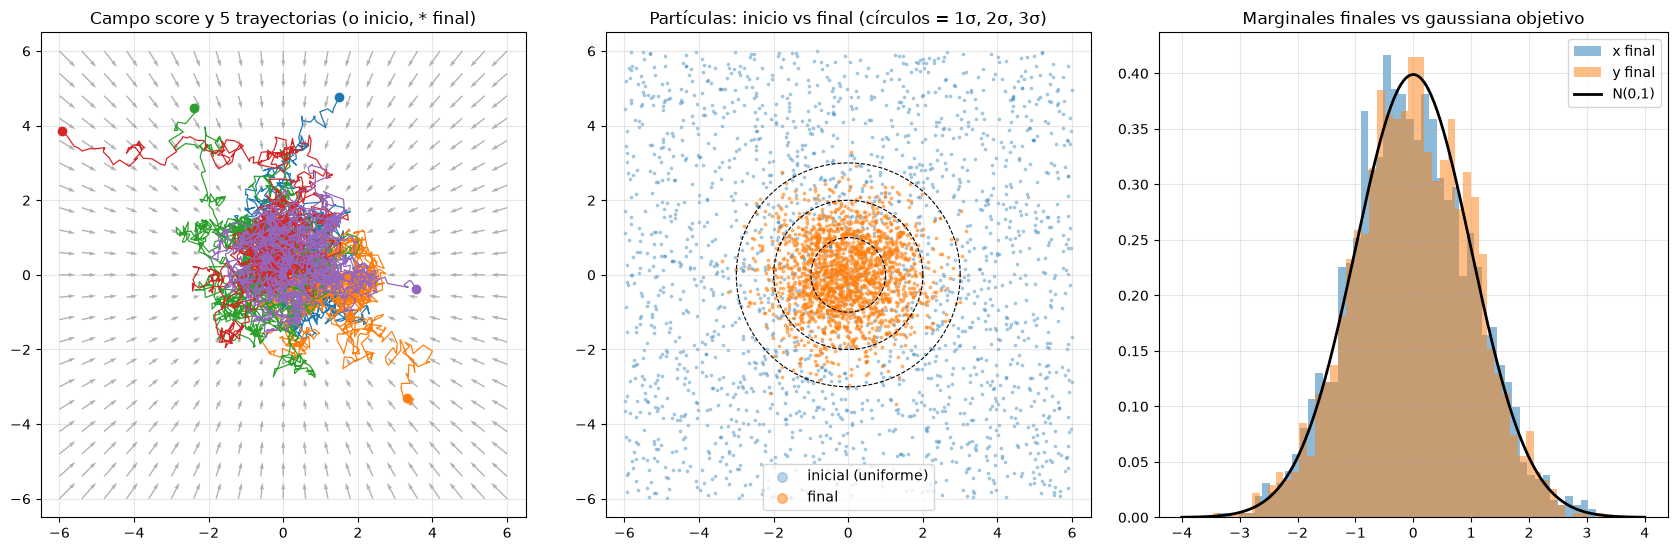

Media final: [-0.03540657  0.00527237]
Covarianza final:
[[1.06092099 0.0216648 ]
 [0.0216648  1.01156566]]
Covarianza teórica con discretización: 1.0050 * I


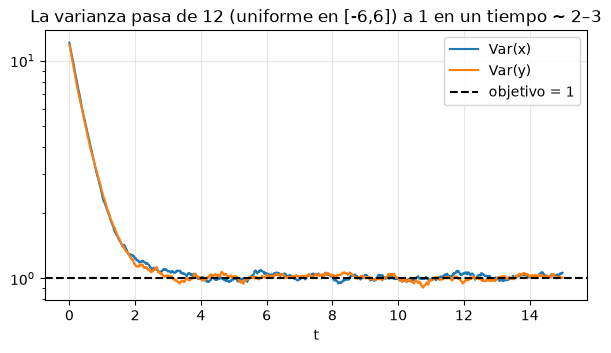

Prueba de Kolmogorov-Smirnov contra N(0,1), eje x: p = 0.026
Prueba de Kolmogorov-Smirnov contra N(0,1), eje y: p = 0.180


In [12]:
# Langevin en 2D con el score de una gaussiana N((0,0), I)
mu2 = np.array([0.0, 0.0])
cov2 = np.eye(2)
cov2_inv = np.linalg.inv(cov2)

def score2(X):
    """s(x) = -Σ^{-1} (x - μ); X tiene forma (n, 2)."""
    return -(X - mu2) @ cov2_inv.T

rng2 = np.random.default_rng(7)
n_part2, n_pasos2, dt2 = 2000, 1500, 0.01

# Posiciones iniciales al azar: uniformes en el cuadrado [-6, 6]^2 (lejos de la distribución objetivo)
X = np.empty((n_pasos2 + 1, n_part2, 2))
X[0] = rng2.uniform(-6, 6, size=(n_part2, 2))
for n in range(n_pasos2):
    eps = rng2.standard_normal((n_part2, 2))
    X[n + 1] = X[n] + score2(X[n]) * dt2 + np.sqrt(2 * dt2) * eps

fig, ax = plt.subplots(1, 3, figsize=(17, 5.6))

# (a) Campo score y cinco trayectorias
g = np.linspace(-6, 6, 21)
GX, GY = np.meshgrid(g, g)
S = score2(np.c_[GX.ravel(), GY.ravel()])
ax[0].quiver(GX, GY, S[:, 0].reshape(GX.shape), S[:, 1].reshape(GX.shape), color="gray", alpha=0.6)
for i in range(5):
    ax[0].plot(X[:, i, 0], X[:, i, 1], lw=0.9)
    ax[0].plot(*X[0, i], "o", color=f"C{i}"); ax[0].plot(*X[-1, i], "*", ms=12, color=f"C{i}")
ax[0].set_title("Campo score y 5 trayectorias (o inicio, * final)")
ax[0].set_aspect("equal"); ax[0].set_xlim(-6.5, 6.5); ax[0].set_ylim(-6.5, 6.5)

# (b) Posiciones iniciales vs finales
ax[1].scatter(X[0, :, 0], X[0, :, 1], s=3, alpha=0.3, label="inicial (uniforme)")
ax[1].scatter(X[-1, :, 0], X[-1, :, 1], s=3, alpha=0.5, label="final")
th = np.linspace(0, 2 * np.pi, 200)
for r in (1, 2, 3):
    ax[1].plot(r * np.cos(th), r * np.sin(th), "k--", lw=0.8)
ax[1].set_title("Partículas: inicio vs final (círculos = 1σ, 2σ, 3σ)"); ax[1].legend(markerscale=4)
ax[1].set_aspect("equal"); ax[1].set_xlim(-6.5, 6.5); ax[1].set_ylim(-6.5, 6.5)

# (c) Comparación de la marginal en x con la gaussiana objetivo
xs = np.linspace(-4, 4, 300)
ax[2].hist(X[-1, :, 0], bins=50, density=True, alpha=0.5, label="x final")
ax[2].hist(X[-1, :, 1], bins=50, density=True, alpha=0.5, label="y final")
ax[2].plot(xs, np.exp(-xs**2 / 2) / np.sqrt(2 * np.pi), "k", lw=2, label="N(0,1)")
ax[2].set_title("Marginales finales vs gaussiana objetivo"); ax[2].legend()
for a in ax: a.grid(alpha=.3)
plt.tight_layout(); plt.show()

media_final = X[-1].mean(axis=0)
cov_final = np.cov(X[-1].T)
print("Media final:", media_final)
print("Covarianza final:")
print(cov_final)
print(f"Covarianza teórica con discretización: {1 / (1 - dt2 / 2):.4f} * I")

# Convergencia en el tiempo
tt = np.arange(n_pasos2 + 1) * dt2
var_t = X.var(axis=1)
plt.figure(figsize=(7, 3.5))
plt.plot(tt, var_t[:, 0], label="Var(x)"); plt.plot(tt, var_t[:, 1], label="Var(y)")
plt.axhline(1, color="k", ls="--", label="objetivo = 1")
plt.yscale("log"); plt.xlabel("t"); plt.legend(); plt.grid(alpha=.3)
plt.title("La varianza pasa de 12 (uniforme en [-6,6]) a 1 en un tiempo ~ 2–3"); plt.show()

# Prueba de normalidad de las marginales
from scipy import stats
for nombre_eje, col in [("x", 0), ("y", 1)]:
    print(f"Prueba de Kolmogorov-Smirnov contra N(0,1), eje {nombre_eje}: p = {stats.kstest(X[-1, :, col], 'norm').pvalue:.3f}")


**Conclusiones**

- **Partícula libre:** la media se mantiene en $x_0 = 0$ y la varianza crece linealmente con pendiente $2D$. Es difusión pura: la partícula se aleja como $\sqrt{t}$.
- **Con resorte $f = -kx$:** la deriva restauradora compite con el ruido. La varianza crece al inicio igual que en el caso libre, pero se satura en $k_BT/k$, con tiempo de relajación $\gamma/(2k)$. La distribución estacionaria es la gaussiana de Boltzmann $p(x) \propto e^{-kx^2/2k_BT}$. Euler–Maruyama introduce un pequeño sesgo, $\operatorname{Var} = \frac{k_BT/k}{1 - k\Delta t/2\gamma}$, que desaparece cuando $\Delta t \to 0$.
- **Langevin con score en 2D:** partículas que empiezan repartidas uniformemente en $[-6,6]^2$ (varianza 12 por eje) son arrastradas por el campo $\mathbf{s}(\mathbf{x}) = -\mathbf{x}$ hacia el origen, mientras el ruido evita que colapsen en un punto. Después de $t \approx 3$ la nube ya es la gaussiana objetivo. La media final es ≈ (−0.04, 0.01) y la covarianza ≈ diag(1.06, 1.01), con covarianza cruzada 0.02. Con 2000 partículas el error estadístico de una varianza es $\sqrt{2/2000} \approx 0.03$, así que estas diferencias con la identidad (y con el factor $1/(1-\Delta t/2) \approx 1.005$ que introduce la discretización) son fluctuaciones de muestreo. En la prueba de Kolmogorov–Smirnov, el eje $y$ es compatible con $\mathcal{N}(0,1)$ ($p = 0.18$). El eje $x$ queda en el límite ($p = 0.03$), por la misma fluctuación de su varianza; con más partículas la diferencia se reduce.

Este es el principio de los **modelos generativos basados en score**: si se conoce (o se aprende con una red) $\nabla_x \log p(x)$, la dinámica de Langevin transforma ruido en muestras de $p$.
